---
title: "Chapter 21: Communication"
---

Building and evaluating models is only part of applied ML. The final section of the book, **Responsible ML Practice**, considers how we explain our work, examine its consequences, and make a trained model available to others. We begin with **communication**, followed by **ethics**, and then **deployment and conclusion**, which includes a practical deployment example and a reflection on the course’s main lessons.

Communication supports the whole workflow: discussing goals, questioning assumptions, and explaining evidence help a team decide what to build and how to use its results responsibly.

::: {.callout-lo}
## Learning outcomes {.unnumbered}

By the end of this chapter, you should be able to:

- Identify why an ML result alone may not answer the question a decision-maker cares about.
- Recognize how an audience’s background and purpose affect the choice of language, examples, and detail.
- Present results with appropriate baselines, context, and recommendations.
- Distinguish model probability estimates from evidence about their reliability.
- Communicate limitations and uncertainty without hiding useful findings.
- Identify misleading visualizations and construct fair comparisons.
:::

**Imports**

In [1]:
#| code-fold: true
#| code-summary: "Show imports and setup"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor, make_column_transformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

DATA_DIR = Path("data") if Path("data").is_dir() else Path("book") / "data"
plt.rcParams["font.size"] = 12

This chapter focuses on three messages: **start from the reader’s needs**, **match the claim to the evidence**, and **make the evidence easy to interpret fairly**. You will practise these through three tasks. Choose and justify an answer before reading each discussion, compare reasoning with a partner if possible, and use what you learn to improve a message.

## Task 1: Explain a method to a newcomer

### Compare two explanations

You already know hyperparameter optimization. Here, focus on how it is explained rather than learning a new method. Read the two original explanations below and consider how they would have felt on Day 1 of CPSC 330. Notice how each begins, what background it assumes, and how it connects code to results. You do not need to understand every parameter.

::: {.callout-note appearance="simple"}
## Explanation 1 {.unnumbered}

Machine learning algorithms, like an airplane's cockpit, typically involve a bunch of knobs and switches that need to be set.

![](https://i.pinimg.com/236x/ea/43/f3/ea43f3c7f3a8c92d884ce012c77628fd--cockpit-gauges.jpg)

For example, check out the documentation of the popular random forest algorithm [here](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html). Here's a list of the function arguments, along with their default values (from the documentation):

> RandomForestClassifier(n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)

Holy cow, that's a lot of knobs and switches! As a machine learning practitioner, how am I supposed to choose `n_estimators`? Should I leave it at the default of 100? Or try 1000? What about `criterion` or `class_weight` for that matter? Should I trust the defaults?

Enter [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) to save the day. The general strategy here is to choose the settings that perform best on the specific task of interest. So I can't say `n_estimators=100` is better than `n_estimators=1000` without knowing what problem I'm working on. For a specific problem, you usually have a numerical score that measures performance. `GridSearchCV` is part of the popular [scikit-learn](https://scikit-learn.org/) Python machine learning library. It works by searching over various settings and compares them using cross-validation on the training data. 

The "grid" in "grid search" comes from the fact that it tries all possible combinations on a grid. For example, if you want it to consider setting `n_estimators` to 100, 150 or 200, and you want it to consider setting `criterion` to `'gini'` or `'entropy'`, then it will search over all 6 possible combinations in a grid of 3 possible values by 2 possible values: 

|                    | `criterion='gini'` | `criterion='entropy'` |
|----------------------|--------|---------|
| `n_estimators=100` |    1     |    2     |
| `n_estimators=150` |    3     |    4     |
| `n_estimators=200` |    5     |    6     |

Here is a code sample that uses `GridSearchCV` to select from the 6 options we just mentioned. The problem being solved is classifying images of handwritten digits into the 10 digit categories (0-9). I chose this because the dataset is conveniently built in to scikit-learn:

In [2]:
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Reserve a test set before comparing settings.
digits = load_digits()
X_digits_train, X_digits_test, y_digits_train, y_digits_test = train_test_split(
    digits.data, digits.target, test_size=0.2, stratify=digits.target, random_state=123
)
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=123),
    param_grid={"n_estimators": [100, 150, 200], "criterion": ["gini", "entropy"]},
)
grid_search.fit(X_digits_train, y_digits_train)
grid_search.best_params_

{'criterion': 'entropy', 'n_estimators': 150}

The output shows which of the six combinations had the highest mean cross-validation score in this search. This does not establish that the settings are universally best; our separate test set remains untouched.

By the way, these “knobs” we've been setting are called **hyperparameters**, and the process of selecting them is called **hyperparameter optimization** or **hyperparameter tuning**.

:::

::: {.callout-note appearance="simple"}
## Explanation 2 {.unnumbered}

The following explanation is reproduced from the [original grid-search article](https://medium.datadriveninvestor.com/an-introduction-to-grid-search-ff57adcc0998), as in the lecture notes. Treat it as material to critique, including its technical wording. The code is shown as text rather than executed because it assumes a dataset `X, y` that the article excerpt does not define.

#### An introduction to Grid Search

<img src="img/hyperparam_meme.png" width="300" height="200">

This article will explain in simple terms what grid search is and how to implement grid search using `sklearn` in python.

##### What is grid search?

Grid search is the process of performing hyper parameter tuning in order to determine the optimal values for a given model. This is significant as the performance of the entire model is based on the hyper parameter values specified.


##### Why should I use it?

If you work with ML, you know what a nightmare it is to stipulate values for hyper parameters. There are libraries that have been implemented, such as `GridSearchCV` of the `sklearn` library, in order to automate this process and make life a little bit easier for ML enthusiasts.


##### How does it work?

Here's a python implementation of grid search using `GridSearchCV` of the `sklearn` library.

```python
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
gsc = GridSearchCV(
        estimator=SVR(kernel='rbf'),
        param_grid={
            'C': [0.1, 1, 100, 1000],
            'epsilon': [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10],
            'gamma': [0.0001, 0.001, 0.005, 0.1, 1, 3, 5]
        },
        cv=5, scoring='neg_mean_squared_error', verbose=0, n_jobs=-1)
```

First, we need to import `GridSearchCV` from the `sklearn` library, a machine learning library for python. The `estimator` parameter of `GridSearchCV` requires the model we are using for the hyper parameter tuning process. For this example, we are using the `rbf` kernel of the Support Vector Regression model(SVR). The `param_grid` parameter requires a list of parameters and the range of values for each parameter of the specified _estimator_. The most significant parameters required when working with the `rbf` kernel of the SVR model are `c`, `gamma` and `epsilon`. A list of values to choose from should be given to each hyper parameter of the model. You can change these values and experiment more to see which value ranges give better performance. A [cross validation process](https://medium.datadriveninvestor.com/k-fold-cross-validation-6b8518070833) is performed in order to determine the hyper parameter value set which provides the best accuracy levels.

```
grid_result = gsc.fit(X, y)
best_params = grid_result.best_params_
best_svr = SVR(kernel='rbf', C=best_params["C"], epsilon=best_params["epsilon"], gamma=best_params["gamma"],
                   coef0=0.1, shrinking=True,
                   tol=0.001, cache_size=200, verbose=False, max_iter=-1)
```

We then use the best set of hyper parameter values chosen in the grid search, in the actual model as shown above.

If you want to know how to use grid search and cross-validation and train and test a model check out [this article](https://medium.datadriveninvestor.com/a-practical-guide-to-getting-started-with-machine-learning-3a6fcc0f95aa).

Hope this article helped you. Until next time…Adios!

:::


::: {.callout-exercise}
### Choose how to explain

Your teammate knows Python but has not studied ML. Use the two explanations above to help you decide.

**1. Which opening would you use to explain why you are trying several random-forest settings?**

A. “We are performing hyperparameter optimization using cross-validation.”

B. “The model has settings we must choose before training. We will compare several choices using held-out portions of our training data.”

C. “Random forests have settings such as `max_depth`, `max_features`, and `n_estimators`.”

What knowledge does each opening assume? When might A be appropriate?

**2. You have room for one worked example. Which plan would you choose?**

A. Introduce random-forest settings, illustrate their combinations in a table, then use those same settings in code and explain the output.

B. Introduce random-forest settings, demonstrate search with support vector regression, then show a result from a third model to illustrate the range of applications.

C. Start with complete search code, then define all its unfamiliar terms in a glossary at the end.

What would the reader need to keep track of in each plan? Could you borrow anything useful from another plan? In Explanation 1, does showing the full random-forest signature help establish the problem, overwhelm the newcomer, or both? How would you revise that choice?

**3. The reader now understands how grid search tries combinations, but asks whether tuning always helps. What would you add next?**

A. A list of more hyperparameters they could tune.

B. A comparison of a default model and a tuned model on the same evaluation data, with the relevant scores beside the code.

C. A diagram showing how the grid-search loop runs.

Explain why your choice addresses this question. Which addition would help if the reader instead asked how the search works?

Choose individually and justify each answer before opening the discussion. If you disagree with a partner, identify which assumption about the reader differs.
:::

<details>
<summary>Discussion after you have chosen</summary>

For this newcomer, **1B** provides a purpose before technical labels; A may be efficient shorthand for an experienced teammate. C gives examples of settings but leaves their purpose unclear. B still assumes the reader understands why we hold out data, so that may need explanation too.

**2A** reduces the number of unfamiliar ideas the reader must connect at once. B could help demonstrate breadth later, once the procedure is understood. C can be useful as a reference for an experienced reader, but a glossary alone does not explain how the pieces fit together.

**3B** supplies evidence about whether tuning helped in this experiment. It does not establish that tuning always helps. C addresses a different question about the procedure; A expands the list without answering either question. Compare the images in the original explanations too: does each clarify an idea, or mainly attract attention?

</details>


### Start from the reader’s needs

Once you understand a method, it is easy to forget what a newcomer needs explained: the **curse of knowledge**. Introduce concepts before relying on their labels. The first explanation starts with settings we must choose and the difficulty of choosing them, then introduces a search procedure. The name comes after the reader has something to attach it to.

Build the explanation in manageable steps and reuse a running example across prose, tables, code, and output. Add contrasts when they answer a question: default versus tuned settings addresses whether tuning helped; grid search versus randomized search clarifies how search methods differ. Put relevant results beside the procedure and explain what to notice.

Choose details and images for what they help the reader understand. An elaborate cockpit analogy may be interesting without helping someone choose settings; it can also mislead if it suggests that an integer tree count can vary continuously. The full constructor signature in Explanation 1 makes the number of choices visible, but a short selection could make the same point with less distraction. Neither explanation is a template to copy unchanged. Keep supporting details available without letting them interrupt the main explanation. For an experienced colleague making a decision, the conclusion may belong first.

Check understanding while others can still influence the work. Ask a specific question such as “Does this split represent how we will use the model?” or invite a colleague to explain what they think the result means. Their response can reveal assumptions your explanation missed.

**Optional video:** In [this short video](https://www.youtube.com/watch?v=px_4TxC2mXU), Richard Feynman distinguishes knowing a name from understanding an idea. What would someone need to explain about grid search to demonstrate understanding beyond naming it?


## Task 2: Help a team decide what to do next

A newcomer may need the concept before its name. A manager may need the conclusion before the method. In both cases, ask what this person needs from the explanation.

Your team is investigating house-price predictions to help staff advise sellers about asking prices. The manager needs to decide whether to fund a limited pilot. You receive this draft update:

> Our model has the best validation score, so we should deploy it. It will help sellers get better prices.

The comparison uses a single training/validation split and several tree counts. A separate test set is reserved. No pilot has measured the effect on asking-price decisions or sale outcomes. Keep this update in view: you will improve its claims here, then choose a visualization for it in Task 3.

::: {.callout-exercise}
### Choose what the manager needs

**1. What is the most useful question to settle before recommending a pilot?**

A. Which algorithm has the highest validation score?

B. How would staff use the predictions, and what would count as a better outcome than their current approach?

C. How many additional hyperparameter combinations can we try?

Explain what your choice would change about the project. Is there still a role for the other questions?

**2. You have two minutes for the update. Which detail would you move to supporting material?**

A. The comparison with the current approach.

B. The full list of hyperparameter combinations tried.

C. An important condition under which the model performs poorly.

What change in audience or purpose could make your chosen detail essential?

**3. You can request one piece of work for the next team meeting. Which would you prioritize?**

A. Compare prediction errors with the estimates staff currently use.

B. Check whether the evaluation data represent the locations and market conditions where the model would be used.

C. Outline a limited pilot that measures changes in staff decisions and seller outcomes.

Each could be useful. Choose one, state an assumption that makes it your priority, and explain what missing information might lead you to choose differently. Identify one claim in the draft that needs qualification.
:::

<details>
<summary>Discussion after you have chosen</summary>

**1B** connects the prediction task to a decision and an objective. A and C may help choose a model, but cannot establish what staff or sellers need.

For this manager, **2B** usually belongs in supporting material. A collaborator reproducing the search may need that list. The baseline and failure conditions affect whether the pilot is worth funding, so they belong in the main update.

**3 has no single best answer without more context.** A addresses the missing comparison with current practice; B addresses whether the measured performance is relevant; C addresses the unmeasured effect of using predictions. For example, if the data come from a different market, B may be the first priority. Explain your assumption rather than treating one next step as universally correct. A more defensible claim is: “The validation comparison can help us select an approach for further evaluation; it does not yet show that using it improves sale outcomes.”

</details>

### Match the claim to the evidence

Start with three questions: **Who will use this? What will they do differently? What counts as improvement?** Here, staff might use predicted sale prices to advise sellers about asking prices. The team needs to establish whether that advice improves on current practice. Predicting a sale price accurately does not establish that acting on the prediction will help a seller obtain a higher price.

The manager needs the evidence, costs, risks, and proposed next step. A teammate reproducing the comparison also needs feature definitions, code, and settings. Adapt the detail to the reader without changing the underlying claim.

Keep these three parts of an update distinct:

| Part | Housing example |
|---|---|
| Observation | On the held-out validation data, the models achieved the scores shown in our comparison. |
| Interpretation | The comparison helps us choose an approach for further evaluation under similar conditions. |
| Recommendation | Check the selected approach on the reserved test set and design a limited pilot to assess whether it improves staff decisions. |

An observation needs a defined target, metric, evaluation setup, and relevant baseline. Our comparison of two algorithms does not yet show an improvement over staff’s current approach. The interpretation depends on how well the evaluation represents intended use; the recommendation also depends on costs and alternatives. In Task 3, you will use the measured scores to make the observation specific.

A score can change with the training/validation split, and repeated searches can make the best validation result look overly optimistic. Keep an untouched test set for final evaluation of the selected approach. Even a strong historical result may not represent new locations, market conditions, or data collection practices. The housing update should identify the conditions evaluated rather than promise future performance everywhere.

Make limitations useful for the decision. Instead of “More data is needed,” ask whether the evaluation covers the locations and market conditions where staff will use the model. State what remains untested and what evidence would resolve it. Keep qualifications beside the claim they limit.

The same distinction between an output and the evidence supporting its use also matters when communicating probabilities. The brief sidebar below considers that case before we return to the housing update.


:::: {.callout-note appearance="simple"}
## Sidebar: a probability is not evidence of reliability {.unnumbered}

A number can look more authoritative than the evidence warrants.

::: {.callout-exercise}
### Check what a probability supports

In a fraud project, a classifier assigns a transaction a probability of 0.9. A colleague says, “This means we are 90% sure the model is trustworthy.” **Which interpretation is most appropriate?**

A. The output tells us that the model is reliable for 90% of transactions.

B. The model estimates a 90% probability of fraud for this transaction; this output alone does not establish the estimate’s reliability.

C. Unless we know whether this transaction is fraudulent, the probability estimate has no useful meaning.

Choose and explain. What additional evidence would you want before relying on the model’s probability estimates?
:::

**B** separates the model’s estimate from evidence about its reliability. A probability of 0.9 is an output of the fitted model, not a statement that we are 90% sure the model is trustworthy. We need relevant held-out outcomes to assess how well its estimates match what actually happens. Uncertainty does not make probabilities useless, but it limits what we can claim from one prediction.

<details>
<summary>Optional: understanding calibration</summary>

To see how we might assess probability estimates, imagine collecting 100 held-out transactions to which the model assigned probabilities near 0.9. If these estimates reflect how often fraud actually occurs, we would expect roughly 90 of those transactions to be fraudulent. If only about 60 are fraudulent, the model’s estimates are too high for that group.

This agreement between estimated probabilities and observed frequencies is called **calibration**. The same idea applies across the probability range: among transactions assigned probabilities near 0.2, roughly 20% should be fraudulent. The counts will vary by chance, especially in small groups, so we look for patterns across enough held-out examples from the population where the model will be used.

A single transaction cannot tell us whether a probability of 0.9 was reliable: the outcome will be either fraud or no fraud, and either is possible. Calibration concerns groups of predictions. Even well-calibrated probabilities do not establish that the whole system is trustworthy or useful for a particular decision.

A model can rank fraudulent transactions well while producing poorly calibrated probabilities. Conversely, assigning every transaction the overall fraud rate might be calibrated in aggregate but unhelpful for choosing which transactions to investigate. An overall calibration pattern can also hide problems for particular groups or conditions.

Chapter 7 introduced the loss used to train logistic regression. Training with a probability-based loss does not by itself demonstrate that the fitted model’s probabilities will be reliable on future data.

</details>


::::

Return to the housing draft. Revise one sentence so it distinguishes the measured result from the hoped-for benefit. Keep it for the final update after you have examined the plots.


## Task 3: Present a fair comparison

Return to the housing-project update from Task 2. The manager needs evidence for the pilot decision. First, prepare a technical comparison for teammates assessing the models. Then choose which finding and supporting visual, if any, belong in the manager’s update. A plot can make a comparison easier to understand, but presentation choices can also make the same results appear to support different stories. Labels, axis ranges, and the examples you choose to show are part of the claim.

To make the housing comparison concrete, we will use the Kaggle data from Chapter 10 and compare random forests with gradient boosting for several tree counts. Our purpose is to examine how plotting choices affect interpretation, rather than to conduct a thorough model search.

The setup and fitting code are folded so you can focus on the results table and plots; open them if you want to inspect the procedure. It fits transformations on the training portion only. We reserve a test set and use a separate validation set for the repeated comparisons below.

In [3]:
#| code-fold: true
#| code-summary: "Show housing data split"
df = pd.read_csv(DATA_DIR / "housing-kaggle" / "train.csv")
train_valid_df, test_df = train_test_split(df, test_size=0.10, random_state=123)
train_df, valid_df = train_test_split(train_valid_df, test_size=0.20, random_state=123)

X_train = train_df.drop(columns=["SalePrice"])
y_train = train_df["SalePrice"]
X_valid = valid_df.drop(columns=["SalePrice"])
y_valid = valid_df["SalePrice"]

In [4]:
#| code-fold: true
#| code-summary: "Show housing preprocessing setup"
drop_features = ["Id"]
numeric_features = [
    "BedroomAbvGr",
    "KitchenAbvGr",
    "LotFrontage",
    "LotArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "BsmtFullBath",
    "BsmtHalfBath",
    "FullBath",
    "HalfBath",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageYrBlt",
    "GarageCars",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal",
    "YrSold",
]

In [5]:
#| code-fold: true
#| code-summary: "Show housing preprocessing setup"
ordinal_features_reg = [
    "ExterQual",
    "ExterCond",
    "BsmtQual",
    "BsmtCond",
    "HeatingQC",
    "KitchenQual",
    "FireplaceQu",
    "GarageQual",
    "GarageCond",
    "PoolQC",
]
ordering = [
    "Po",
    "Fa",
    "TA",
    "Gd",
    "Ex",
]  # if N/A it will just impute something, per below
ordering_ordinal_reg = [ordering] * len(ordinal_features_reg)
ordering_ordinal_reg

[['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
 ['Po', 'Fa', 'TA', 'Gd', 'Ex']]

In [6]:
#| code-fold: true
#| code-summary: "Show housing preprocessing setup"
ordinal_features_oth = [
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "Functional",
    "Fence",
]
ordering_ordinal_oth = [
    ["NA", "No", "Mn", "Av", "Gd"],
    ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    ["NA", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    ["NA", "MnWw", "GdWo", "MnPrv", "GdPrv"],
]

In [7]:
#| code-fold: true
#| code-summary: "Show housing preprocessing setup"
categorical_features = [
    column for column in X_train.columns
    if column not in numeric_features + ordinal_features_reg + ordinal_features_oth + drop_features
]

In [8]:
#| code-fold: true
#| code-summary: "Show housing preprocessing setup"
numeric_transformer = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
ordinal_transformer_reg = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(categories=ordering_ordinal_reg),
)

ordinal_transformer_oth = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(categories=ordering_ordinal_oth),
)

categorical_transformer = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="missing"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessor = make_column_transformer(
    ("drop", drop_features),
    (numeric_transformer, numeric_features),
    (ordinal_transformer_reg, ordinal_features_reg),
    (ordinal_transformer_oth, ordinal_features_oth),
    (categorical_transformer, categorical_features),
)

In [9]:
#| code-fold: true
#| code-summary: "Show model fitting code"
n_estimators_values = [3, 10, 30, 100, 300]
records = []
for model_name, estimator in [
    ("Random forest", RandomForestRegressor(random_state=123)),
    ("Gradient boosting", GradientBoostingRegressor(random_state=123)),
]:
    for n_estimators in n_estimators_values:
        model = make_pipeline(
            clone(preprocessor),
            TransformedTargetRegressor(
                regressor=clone(estimator).set_params(n_estimators=n_estimators),
                func=np.log1p,
                inverse_func=np.expm1,
            ),
        )
        model.fit(X_train, y_train)
        records.append({
            "model": model_name,
            "n_estimators": n_estimators,
            "train_r2": model.score(X_train, y_train),
            "validation_r2": model.score(X_valid, y_valid),
        })
results = pd.DataFrame(records)
display(results)

,model,n_estimators,train_r2,validation_r2
0,Random forest,3,0.941423,0.760256
1,Random forest,10,0.973747,0.869104
2,Random forest,30,0.976957,0.867210
3,Random forest,100,0.978577,0.869014
4,Random forest,300,0.978045,0.871251
5,Gradient boosting,3,0.260023,0.312821
6,Gradient boosting,10,0.633202,0.651561
7,Gradient boosting,30,0.891737,0.866797
8,Gradient boosting,100,0.966897,0.905721
9,Gradient boosting,300,0.988798,0.913425


Both models are trained using a log-transformed target, with predictions converted back to dollars before calculating $R^2$. The validation scores below therefore assess predictions on the original price scale. These are single-split comparisons with mostly default settings. Equal tree counts do not mean equal computation or equally thorough tuning of the two methods.

::: {.callout-exercise}
### Predict how the story could change

Before viewing the plots, inspect the table. Your technical teammates ask how the two methods compare across the tree counts tried. Which presentation would you choose?

A. Show only the smaller tree counts where the difference is easiest to explain.

B. Show all five settings with clearly labelled axes and a shared vertical scale, separating training and validation results.

C. Show all five settings on a vertical scale wide enough that the curves look almost identical.

Justify your choice in terms of your teammates' question. Predict how A or C could change the apparent conclusion. Under what stated constraint might showing only smaller models be reasonable?
:::

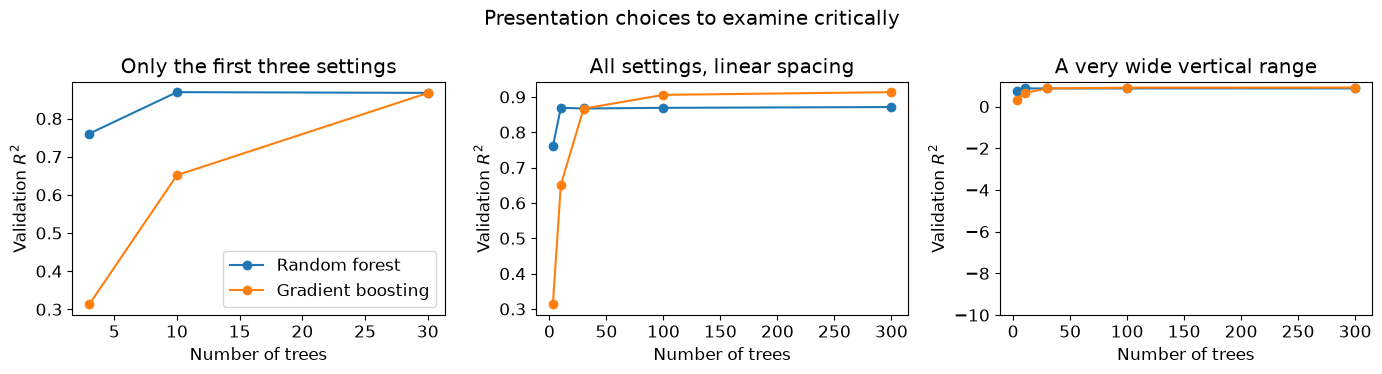

In [10]:
#| code-fold: true
#| code-summary: "Show plotting code"
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for model_name, group in results.groupby("model", sort=False):
    early = group.iloc[:3]
    axes[0].plot(early["n_estimators"], early["validation_r2"], marker="o", label=model_name)
    axes[1].plot(group["n_estimators"], group["validation_r2"], marker="o", label=model_name)
    axes[2].plot(group["n_estimators"], group["validation_r2"], marker="o", label=model_name)
axes[0].set_title("Only the first three settings")
axes[1].set_title("All settings, linear spacing")
axes[2].set_title("A very wide vertical range")
axes[2].set_ylim(-10, 1.2)
for ax in axes:
    ax.set(xlabel="Number of trees", ylabel="Validation $R^2$")
axes[0].legend()
fig.suptitle("Presentation choices to examine critically")
fig.tight_layout()
plt.show()

**B** preserves the settings needed to answer the stated question. Compare that choice with the three panels above. The first panel omits the larger ensembles. That might be a reasonable restriction if only small models were feasible, but it needs to be stated and justified. Otherwise it can hide where the comparison changes. The second panel includes every setting, yet linear spacing compresses the smaller tree counts. The third uses a vertical range so wide that differences become difficult to see.

These examples illustrate why a plot needs both a clear question and an explanation of its scope. A restricted range is not inherently dishonest. The issue is whether the display supports the claim being made or conceals relevant evidence.

### Show a fair comparison

Use a shared vertical scale when comparing the same metric, show the settings relevant to the question, and explain any non-linear axis. Here, a logarithmic horizontal axis makes multiplicative increases in tree count easier to compare. Separate panels keep training and validation results distinct.

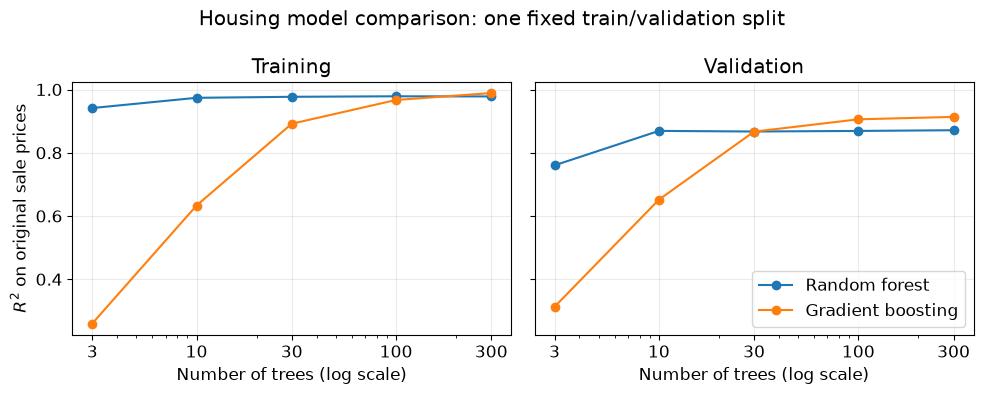

In [11]:
#| code-fold: true
#| code-summary: "Show plotting code"
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for model_name, group in results.groupby("model", sort=False):
    for ax, column in zip(axes, ["train_r2", "validation_r2"]):
        ax.plot(group["n_estimators"], group[column], marker="o", label=model_name)
for ax, title in zip(axes, ["Training", "Validation"]):
    ax.set_xscale("log")
    ax.set_xticks(n_estimators_values, labels=n_estimators_values)
    ax.set(xlabel="Number of trees (log scale)", title=title)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("$R^2$ on original sale prices")
axes[1].legend()
fig.suptitle("Housing model comparison: one fixed train/validation split")
fig.tight_layout()
plt.show()

This display allows us to compare the measured scores across all five settings. It does not establish that one algorithm is generally superior. Another split, different hyperparameters, or a different metric could change the comparison. The test set remains untouched; a final evaluation would come after choosing the approach.

When reviewing a visualization, check whether the axis ranges exaggerate or obscure differences, whether values or settings have been selectively omitted, and whether colours and labels make the comparison clear. Dual vertical axes are particularly risky for comparing two series because independently chosen scales can make them appear to agree or diverge.

Bar charts generally need a zero baseline because bar lengths encode magnitude. Line and scatter plots need not always start at zero; a narrower range can reveal useful variation. Make the scale clear and choose it to answer the question fairly. When areas or volumes encode quantities, their sizes should be proportional to those quantities rather than visually exaggerating differences.

<details>
<summary>Optional: other visualization pitfalls and a headline to critique</summary>

Chart choice matters too. In a histogram of prediction errors, changing the bin widths or boundaries can make the same errors look concentrated, spread out, or clustered into separate groups. Use bins that help answer the question, and check whether an apparent pattern depends on one particular choice.

Decoration can also compete with the evidence. A house-shaped graphic might attract attention to a housing-price comparison while making values harder to compare than simple points or bars. Start with the comparison readers need to make, then choose a chart that supports it. Do not force data into an attractive visual form that obscures the quantities or relationships. The visualization resources below call these pitfalls “dataviz ducks” and “glass slippers,” respectively; recognizing the problem matters more than remembering the labels.

For further examples, see the [Calling Bullshit visualization videos](https://www.youtube.com/playlist?list=PLPnZfvKID1Sje5jWxt-4CSZD7bUI4gSPS) and this [demonstration of simplifying a chart](https://www.darkhorseanalytics.com/blog/data-looks-better-naked).
![A headline to examine critically.](img/ml-communication.png){width=650}

Before accepting a model-performance headline, ask what task was evaluated, on which population, against which baseline, and using which metric. What additional evidence would you need before treating the result as useful in practice?


</details>

::: {.callout-exercise}
### Complete the housing update

Rewrite the draft from Task 2 for the manager, using the fair comparison. Begin with the sentence you revised earlier. In at most 100 words, report a specific measured result and its comparison, a limitation that affects the decision, and a justified next step. Explain how the result relates to the manager’s question without claiming that better sale outcomes have been measured. Choose what belongs in the main message and what should be supporting material. Would this manager benefit from the full technical plot, a simpler visual, or a sentence reporting the comparison? Justify your choice. Do not invent benefits to sellers.

Exchange updates with a partner if possible. Ask them to describe what decision your update supports and what remains unknown. Revise any wording that led them to a stronger conclusion than you intended.
:::

<details>
<summary>One possible update: read after writing</summary>

> On one held-out split of historical sales, gradient boosting with 300 trees achieved an $R^2$ score of 0.913, compared with 0.871 for a random forest with 300 trees (this measure compares prediction errors with variation in sale prices; higher is better). We have not compared either model with staff estimates or measured benefits to sellers. I recommend checking whether these data represent our intended market and defining a pilot before committing to deployment. Which staff decisions should the pilot improve, and how would we measure that improvement?

The **observation** reports validation results from the table, not deployment outcomes. The **limitations** identify missing evidence that affects the manager’s decision. The **recommendation and question** connect the next work to intended use. For technical teammates, provide the full comparison and evaluation setup. For the manager, explain the measure further if needed; do not present it as percentage accuracy or a percentage improvement in sale prices.

Here, a sentence carries the main comparison and the technical plot can be supporting material. A simpler visual may be useful if the manager needs to compare more alternatives. Other priorities are reasonable if you explain the assumptions behind them.

</details>


## Try it in a different setting

::: {.callout-exercise}
### Write an update without answer options

A team wants to reduce the time staff spend routing customer-support requests. A classifier assigns each request to a department. On a random held-out sample of historical requests, its accuracy is 88%; always choosing the most common department gives 70%. The model uses only text available when a request arrives. Requests sent to the wrong department must be rerouted manually. You have not measured time saved, and a new product launch may change the kinds of requests received.

Write an update of at most 120 words for the support manager, who must decide whether to fund a pilot and has no ML background. Explain what the result supports, what remains uncertain, and what you recommend doing next. Include one specific question for the manager. Do not invent measurements.

Then explain two choices you made in the wording or selection of details. Finally, identify what you would add for a technical teammate checking the evaluation.
:::

<details>
<summary>Review after writing</summary>

Does your update make the comparison understandable without relying on ML jargon? Does it distinguish routing accuracy from staff time saved? Have you explained why historical performance may not represent requests after the product launch? Your next step should address a specific unanswered question, and your question for the manager should help establish the decision, costs of mistakes, or evidence needed. Several recommendations can be reasonable if you justify them with the facts given.

</details>

## Chapter summary

**Start from the reader’s needs.** Choose language, examples, and detail that help this audience understand the idea or make a decision.

**Match the claim to the evidence.** Distinguish what you observed from what you think it means and what you recommend. Make uncertainty specific enough to guide action.

**Make the evidence easy to interpret fairly.** Show relevant comparisons and choose visualizations that reveal the evidence needed to assess the claim.

Before sharing, ask:

- What does this reader need?
- What does the evidence support?
- Does the presentation make that evidence clear?
- What next step is justified?

**Attribution.** The explanation activities and principles are adapted from [DSCI 542](https://github.com/UBC-MDS/DSCI_542_comm-arg), created by [David Laing](https://davidklaing.com/). The visualization material benefited from discussions with [DSCI 531](https://github.com/UBC-MDS/DSCI_531_viz-1) instructors.